# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Audrey, Claire, Jonathan"

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

1. What is the main idea behind an autoencoder? 

An autoencoder reconstructs a set of input observations that can be used for different applications.  

2. What is the role of the bottleneck layer?  

The bottleneck layer minimizes the size of the input so the observations can be more easily observed.

3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  

Reduces the number of dimensions of thge input observation by dimensionality reduction which can deal with very large amounts of data efficently becuase it trains in mini batches. They are also often used to perform anomoly detection. 

4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?

A key difference between the two is that an autoencoder does its processing in mini batches while PCA does the entire dataset at one time. Autoenconders are also more felxible in that they can do non linear transformations. 


USE AS MANY MARKDOWN CELLS AS NEEDED

## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [3]:
!pip install scikit-learn pandas matplotlib liac-arff


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [4]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, n_retries=5, delay=2, parser="liac-arff")
X, y = mnist.data, mnist.target.astype(int)

In [5]:
# USE AS MANY CELLS AS NEEDED


In [6]:
!pip install numpy
!pip install torch
import numpy as np


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


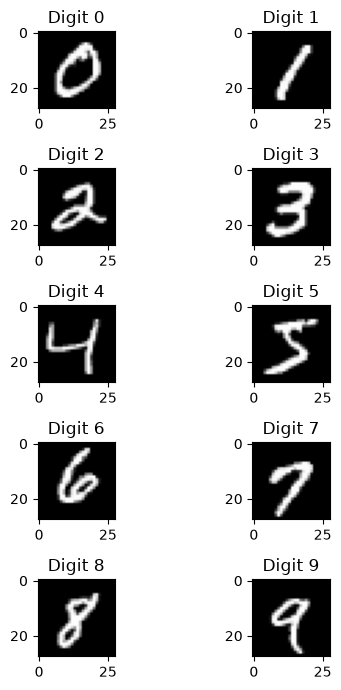

In [7]:
import torch
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pylab as plt
import numpy as np


X = X / 255.0

fig, axis = plt.subplots(figsize=(5, 7), ncols=2, nrows=5)
axis = axis.flatten()

for i_digit in np.unique(y):
    axis[i_digit].imshow(X[y == i_digit][0, :].reshape(28, 28), cmap="gray")
    axis[i_digit].set_title(f"Digit {i_digit}")

plt.tight_layout()

In [8]:
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

X_fit, X_rest, y_fit, y_rest = train_test_split(X, y, random_state=0, test_size=0.30, stratify=y)
X_tune, X_report, y_tune, y_report = train_test_split(X_rest, y_rest, random_state=0, test_size=0.50, stratify=y_rest)

batch_size = 128

fit_dataset = TensorDataset(X_fit, y_fit)
fitting_loader = DataLoader(fit_dataset, batch_size=batch_size, shuffle=True)

tune_dataset = TensorDataset(X_tune, y_tune)
tuning_loader = DataLoader(tune_dataset, batch_size=batch_size, shuffle=False)

reporting_dataset = TensorDataset(X_report, y_report)
reporting_loader = DataLoader(reporting_dataset, batch_size=batch_size, shuffle=False)

## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [9]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            # 784 -> 128 (hidden layer: linear, batch norm, ReLU, dropout)
            nn.Linear(784, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            # 128 -> 64 (hidden layer)
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(p=0.2),
            # 64 -> 2 (bottleneck: only a linear transformation)
            nn.Linear(64, 2),
        ]
        self.encoder_list = nn.ModuleList(encoder_list)

        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            # 2 -> 64 (hidden layer)
            nn.Linear(2, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(p=0.2),
            # 64 -> 128 (hidden layer)
            nn.Linear(64, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            # 128 -> 784 (output layer: linear, then sigmoid so every pixel is between 0 and 1)
            nn.Linear(128, 784), nn.Sigmoid(),
        ]
        self.decoder_list = nn.ModuleList(decoder_list)

    def forward(self, X):
        for layer in self.encoder_list:
            X = layer(X)
        for layer in self.decoder_list:
            X = layer(X)
        output = X
        return output

### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?
- Based on this, which cost function is most appropriate for this task? Justify your choice.

**Why do you think the output layer of the autoencoder above uses a Sigmoid activation?**

In Section 2 we divided every pixel by 255, so all the pixel values in every image are between 0 and 1, and the autoencoder is trying to rebuild that same image. That means every output also has to be between 0 and 1. The sigmoid takes any number and squashes it into the range from 0 to 1, so every reconstructed pixel is always a valid pixel value, where 0 is black and 1 is white. Without it, the last linear layer could output negative values or values above 1, which don't make sense as pixels and could never match the input exactly.

**Based on this, which cost function is most appropriate for this task? Justify your choice.**

We used mean squared error nn.MSELoss. The pixel values we are trying to rebuild are continuous numbers between 0 and 1 (a lot of the pixels on the edges of the strokes are gray, not just black or white), so rebuilding an image is basically a regression problem for each of the 784 pixels. MSE takes the squared difference between each original pixel and its reconstruction and averages it, so it directly measures how close the rebuilt image is to the real one, and it is 0 when the reconstruction is perfect. Because the sigmoid keeps every prediction between 0 and 1, the predictions are always on the same scale as the targets. Squaring the errors also punishes big mistakes (like a black pixel where the digit should be white) more than small ones.

Binary cross-entropy nn.BCELoss would also work with a sigmoid output, and a lot of MNIST autoencoders use it by treating each pixel as the probability of being "on". But BCE is really made for 0/1 targets. When the target pixel is gray, its lowest possible value is not 0, so even a perfect reconstruction would still have some cost, which makes the numbers harder to interpret. Since our goal is to rebuild continuous pixel values, MSE is the most natural choice.

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [10]:
import torch.optim as optim

torch.manual_seed(42)  # same starting weights and batch order every time we run it

# TODO: Replace None to instantiate the autoencoder
model = Autoencoder()

# TODO: Replace None with the appropriate Loss function from 'torch.nn'
# Hint: we are reconstructing continuous pixel values in [0,1]
criterion = nn.MSELoss()
# TODO: Replace None with Adam optimizer.
# Use learning rate of 0.001 and an L2 regularization via weight_decay of 1e-5
optimizer = optim.Adam(model.parameters(), lr = 0.001, weight_decay = 1e-5)

In [11]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            # --- Implement the standard training steps ---
            
            outputs = model(X_batch)            # forward pass for this batch
            cost = criterion(outputs, X_batch)  # the target is the input image itself
            cost.backward()                     # backward pass (compute gradients)
            optimizer.step()                    # update model parameters
            optimizer.zero_grad()               # set gradients back to zero
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = model(X_batch)            # forward pass for tuning data
                cost = criterion(outputs, X_batch)  # tuning cost
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history


Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [12]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.06380  Tuning Cost: 0.04938
Epoch [2/50]  Fitting Cost: 0.04999  Tuning Cost: 0.04670
Epoch [3/50]  Fitting Cost: 0.04851  Tuning Cost: 0.04559
Epoch [4/50]  Fitting Cost: 0.04777  Tuning Cost: 0.04493
Epoch [5/50]  Fitting Cost: 0.04751  Tuning Cost: 0.04467
Epoch [6/50]  Fitting Cost: 0.04712  Tuning Cost: 0.04436
Epoch [7/50]  Fitting Cost: 0.04704  Tuning Cost: 0.04417
Epoch [8/50]  Fitting Cost: 0.04689  Tuning Cost: 0.04407
Epoch [9/50]  Fitting Cost: 0.04679  Tuning Cost: 0.04401
Epoch [10/50]  Fitting Cost: 0.04666  Tuning Cost: 0.04385
Epoch [11/50]  Fitting Cost: 0.04662  Tuning Cost: 0.04379
Epoch [12/50]  Fitting Cost: 0.04657  Tuning Cost: 0.04373
Epoch [13/50]  Fitting Cost: 0.04659  Tuning Cost: 0.04363
Epoch [14/50]  Fitting Cost: 0.04647  Tuning Cost: 0.04356
Epoch [15/50]  Fitting Cost: 0.04645  Tuning Cost: 0.04346
Epoch [16/50]  Fitting Cost: 0.04639  Tuning Cost: 0.04342
Epoch [17/50]  Fitting Cost: 0.04633  Tuning Cost: 0.04334
Epoch 

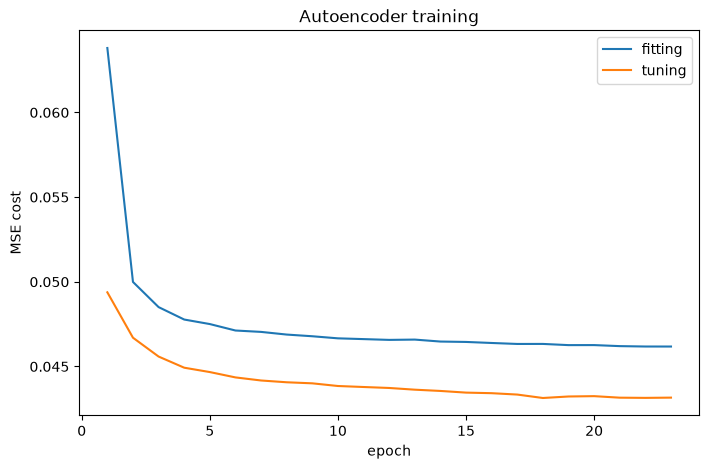

In [13]:
# fitting and tuning cost after each epoch
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(history["fitting"]) + 1), history["fitting"], label="fitting")
plt.plot(range(1, len(history["tuning"]) + 1), history["tuning"], label="tuning")
plt.xlabel("epoch")
plt.ylabel("MSE cost")
plt.title("Autoencoder training")
plt.legend()
plt.show()

### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

In [14]:
# reconstruct the reporting set and compute its cost
model.eval()
originals, reconstructions, digit_labels = [], [], []
with torch.no_grad():
    for X_batch, y_batch in reporting_loader:
        originals.append(X_batch)
        reconstructions.append(model(X_batch))
        digit_labels.append(y_batch)
originals = torch.cat(originals)
reconstructions = torch.cat(reconstructions)
digit_labels = torch.cat(digit_labels)

print("reporting cost (MSE):", round(criterion(reconstructions, originals).item(), 4))

reporting cost (MSE): 0.0427


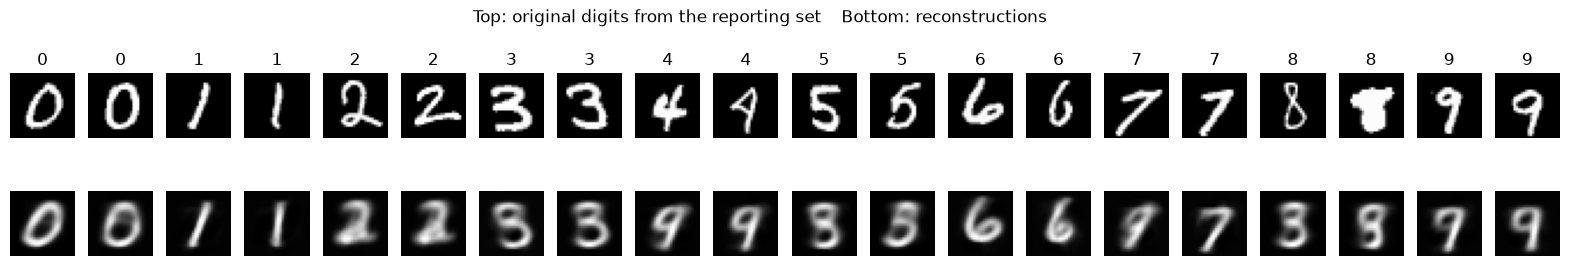

In [15]:
# two examples of each digit from the reporting set: originals on top, reconstructions below
idx = [i for d in range(10) for i in torch.where(digit_labels == d)[0][:2].tolist()]

fig, axes = plt.subplots(2, len(idx), figsize=(20, 2.8))
for col, i in enumerate(idx):
    axes[0, col].imshow(originals[i].reshape(28, 28), cmap="gray")
    axes[1, col].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[0, col].set_title(digit_labels[i].item())
    axes[0, col].axis("off")
    axes[1, col].axis("off")
fig.suptitle("Top: original digits from the reporting set    Bottom: reconstructions", y=1.05)
plt.show()

**Was the reconstruction good?** partly. The reporting cost (MSE of 0.0427) is about the same as the best tuning cost (0.0431), so the model works just as well on digits it has never seen. But looking at the pictures, the reconstructions are a lot blurrier than the originals. About 14 of the 20 still look like the right digit, like the 0s, 1s, 2s, 3s and 6s, and the 1s even keep their slant. But most of the details are gone.

This makes sense because the blurriness also comes from using MSE. When the model isn't sure which digit it is looking at the reconstruction with the lowest MSE is an average of all the digits that could be at that spot and an average of different digits looks blurry. A bigger bottleneck would probably give much sharper reconstructions but then we couldn't plot it in 2D like in Section 4.

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [16]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            encoded = None  # TODO: Apply the encoder part of the model to get the latent features
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [17]:
# latents_autoencoder, labels = extract_latent_features(model, reporting_loader)

In [18]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            # pass the batch through the encoder layers only (stops at the 2D bottleneck)
            encoded = X_batch
            for layer in model.encoder_list:
                encoded = layer(encoded)
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

In [19]:
latents_autoencoder, labels = extract_latent_features(model, reporting_loader)
print("latent features shape:", latents_autoencoder.shape)

latent features shape: (10500, 2)


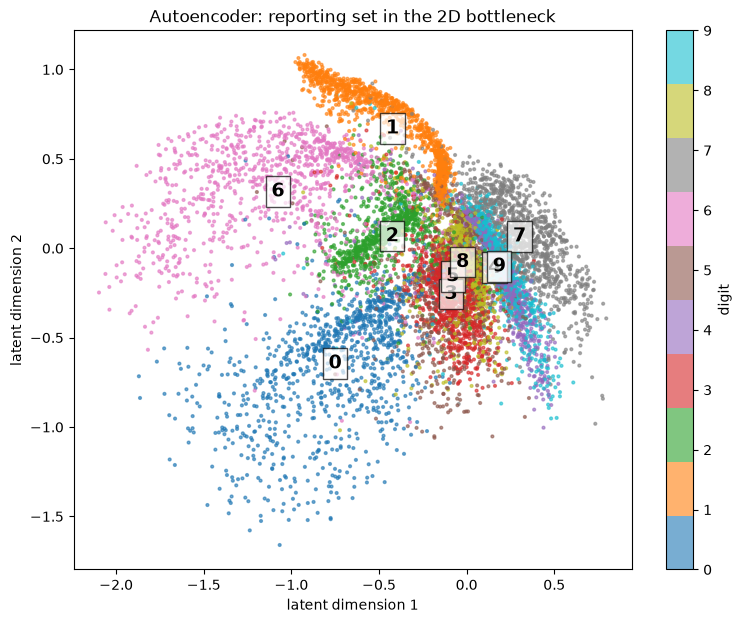

In [22]:
# each reporting digit as a point in the 2D bottleneck space, colored by its label
plt.figure(figsize=(9, 7))
scatter = plt.scatter(latents_autoencoder[:, 0], latents_autoencoder[:, 1],
                      c=labels, cmap="tab10", s=4, alpha=0.6)
plt.colorbar(scatter, ticks=range(10), label="digit")

# write each digit at the center of its cluster so the plot is easier to read
for d in range(10):
    center = latents_autoencoder[labels == d].mean(axis=0)
    plt.text(center[0], center[1], str(d), fontsize=14, weight="bold",
             ha="center", va="center", bbox=dict(facecolor="white", alpha=0.7))

plt.xlabel("latent dimension 1")
plt.ylabel("latent dimension 2")
plt.title("Autoencoder: reporting set in the 2D bottleneck")
plt.show()

Even though the autoencoder never saw the labels, digits of the same class mostly ended up grouped together. Some digits, like 0 and 1, form clear separate clusters, but others overlap a lot, like 4, 7 and 9. These digits look alike, so the encoder gives them similar codes. This also explains why their reconstructions in 3.3 were blurry: when digits overlap in the latent space, the decoder can only output a blend of them.

## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

In [21]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE